## **Σ estimation error and regularization**

To construct the unbiased sample covariance for an investment portfolio, we use the formula

$$S_{ij}=\frac{1}{T-1}\sum_{t=1}^{T}(r_{i,t}-\bar r_i)(r_{j,t}-\bar r_j)$$

which can be written in matrix notation as

$$S_{ij}=\frac{1}{T-1} X^T X$$

In [1]:
import numpy as np
import pandas as pd

In [2]:
# Define a sample return matrix
return_matrix = np.array([
    [3, 7],
    [2, 4],
    [1, 4]
])

In [3]:
def sample_covariance(returns):
    #1. Number of assets
    T_obs = returns.shape[0]

    #2. Mean
    mu = returns.mean(axis=0, keepdims = True)

    # 3.Demeaned returns
    demeaned_returns = returns - mu

    #4. Sample covariance
    return (demeaned_returns.T @ demeaned_returns) / (T_obs - 1)

sample_covariance(return_matrix)

array([[1. , 1.5],
       [1.5, 3. ]])

**Construct a true $\Sigma$ with $N = 35$ (the size of the IPC) based on a one-factor model: $\Sigma = \sigma_m^2\beta\beta^\top + D$, using:**
- $\beta_i \sim U(0.5, 1.5)$
- $\sigma_m = 0.01$ (daily)
- idiosyncratic volatilities $\sim U(0.01, 0.02)$ on the diagonal of $D$
- seed 42.

In [4]:
seed = 42
rng = np.random.default_rng(seed)

N = 35

beta = rng.uniform(1,1.5, size=N)
sigma_m = 0.01
idio_vol = rng.uniform(0.01, 0.02, size=N)

Sigma = sigma_m**2 * np.outer(beta, beta) + np.diag(idio_vol)

(35, 35) True


<Axes: >

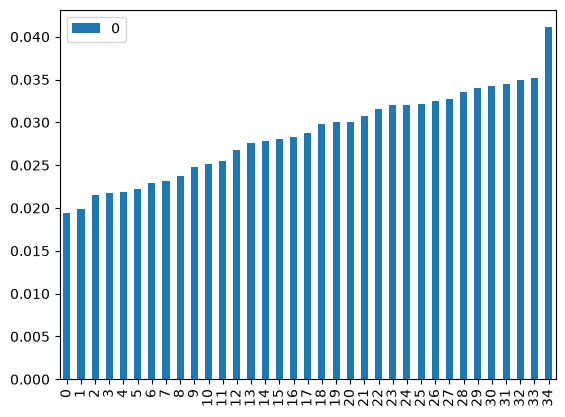

In [5]:
# Pruebas
print(Sigma.shape, np.allclose(Sigma, Sigma.T))

eigs = np.linalg.eigvalsh(Sigma)
eigs
participation = []
total_eigs = eigs.sum()

for eig in eigs:
    participation.append(eig / total_eigs)

participation = pd.DataFrame(participation)
participation.plot(kind="bar")


**For T $\in$ {30, 40, 60, 120, 250, 500, 1000, 5000}, perform 200 replications:**
- Simulate normal returns
- Estimate S and record the ordered eigenvalues
- λ_min
- λ_max
- Condition number
- Relative Frobenius error $\|S-\Sigma\|_F/\|\Sigma\|_F$.

In [6]:
# Lets begin with an example matrix
sigma_example = np.array([
    [4, 2],
    [2, 5]
])

In [ ]:
# Define the shape of our returns matrix: T days, N assets
N = sigma_example.shape[0]
T = 100000

# 1. Apply Cholesky decomposition to the covariance matrix Sigma
L = np.linalg.cholesky(sigma_example)

Z = rng.standard_normal((T, N))

R = Z @ L.T

S = sample_covariance(R)

In [8]:
eigs = np.linalg.eigvalsh(S)

In [9]:
eigs = np.linalg.eigvalsh(S)
# Min and Max  eigenvalues
eig_min = eigs[0]
eig_max = eigs[-1]

# Condition number
condition_number = eig_max / eig_min

# Relative Frobenius error
rel_frobenius_error = np.linalg.norm(S - sigma_example, 'fro') / np.linalg.norm(sigma_example, 'fro')

### **Once we understand the process, we can build functions of it and begin the exercise**

In [10]:
def simulate_returns(Sigma, T, rng, mu=None):
    L = np.linalg.cholesky(Sigma) # 1. Apply Cholesky decomposition to the covariance matrix Sigma
    N = Sigma.shape[0]
    Z = rng.standard_normal((T, N)) # 2. Generate random noise. Mean 0, standard deviation 1
    R = Z @ L.T # 3. Compute the returns

    if mu is not None:
        R = R + mu

    return R

In [11]:
def spectrum_stats(S):
    """
    Inputs a covariance matrix
    Returns the spectrum stats in the following order:
    Ordered eigenvalues, Min eigenvalue, Max eigenvalue, Condition number
    """
    eigs = np.linalg.eigvalsh(S)
    eig_min = eigs[0]
    eig_max = eigs[-1]
    condition_number = eig_max / eig_min

    return eigs, eig_min, eig_max, condition_number


In [12]:
def relative_frobenius_error(Sigma, S):
    """
    Inputs a true covariance matrix and an estimation
    Outputs the Relative Frobenius Error
    """
    return np.linalg.norm(S - Sigma, 'fro') / np.linalg.norm(Sigma, 'fro')

In [13]:
# 1. Define the basic info for the simulation
T_values= np.array([30, 40, 60, 120, 250, 500, 1000, 5000])
n_replications = 200


# 2. Begin the simulation
for t in T_values:
    for rep in range(n_replications):
        R = simulate_returns(Sigma = Sigma, T = t, rng = rng)
        S = sample_covariance(R)
        eigs, eig_min, eig_max, condition_number = spectrum_stats(S)
        rel_frobenius_error = relative_frobenius_error(Sigma=Sigma, S=S)

